# 02 — Exploratory Data Analysis

EDA is performed **before model training** to understand distributions, relationships, categorical composition, outliers, and the target variable.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "Crop Yield Data.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)

Project root: /tmp/cropsel/Crop Yield Prediction
Dataset: /tmp/cropsel/Crop Yield Prediction/data/Crop Yield Data.csv


In [2]:
df = pd.read_csv(DATA_PATH)
df_no_target_na = df.dropna(subset=["Yield"]).copy()
print("Shape used for EDA:", df_no_target_na.shape)
display(df_no_target_na.describe(include="all").T.head(20))

Shape used for EDA: (19688, 13)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Crop,19688,55,Rice,1197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop_Year,19688.0,NaN,NaN,NaN,2009.128098,6.497863,1997.0,2004.0,2010.0,2015.0,2020.0
Season,19688,6,Kharif,8231,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,19688,30,Karnataka,1432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area,19688.0,NaN,NaN,NaN,179935.330546,732846.256704,0.5,1390.0,9318.5,75119.0,50808100.0
Production,19688.0,NaN,NaN,NaN,16436775.81151,263063494.641633,0.0,1392.5,13804.5,122729.5,6326000000.0
Annual_Rainfall,19686.0,NaN,NaN,NaN,1437.461001,816.24921,301.3,940.7,1247.0,1643.7,6552.7
Fertilizer,19686.0,NaN,NaN,NaN,24106865.485154,94952802.534757,54.17,188068.145,1235282.52,10007733.475,4835406877.0
Pesticide,19686.0,NaN,NaN,NaN,48850.952928,213302.82553,0.09,356.76,2422.38,20037.375,15750511.0
Yield,19688.0,NaN,NaN,NaN,79.958031,878.328319,0.0,0.6,1.03,2.389,21105.0


In [3]:
numeric = df_no_target_na.select_dtypes(include=np.number).columns
categorical = df_no_target_na.select_dtypes(exclude=np.number).columns
print("Numeric columns:", list(numeric))
print("Categorical columns:", list(categorical))
for c in categorical:
    print(f"\n{c} — {df_no_target_na[c].nunique()} unique values")
    display(df_no_target_na[c].value_counts().head(10).to_frame("Count"))

Numeric columns: ['Crop_Year', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield', 'Avg_Temperature', 'Max_Temperature', 'Min_Temperature']
Categorical columns: ['Crop', 'Season', 'State']

Crop — 55 unique values


,Count
Crop,
Rice,1197
Maize,975
Moong(Green Gram),740
Urad,733
Groundnut,725
Sesamum,685
Potato,628
Sugarcane,605
Wheat,545



Season — 6 unique values


,Count
Season,
Kharif,8231
Rabi,5742
Whole Year,3717
Summer,1195
Autumn,414
Winter,389



State — 30 unique values


,Count
State,
Karnataka,1432
Andhra Pradesh,1266
West Bengal,1094
Chhattisgarh,915
Bihar,896
Madhya Pradesh,845
Uttar Pradesh,825
Tamil Nadu,822
Gujarat,817


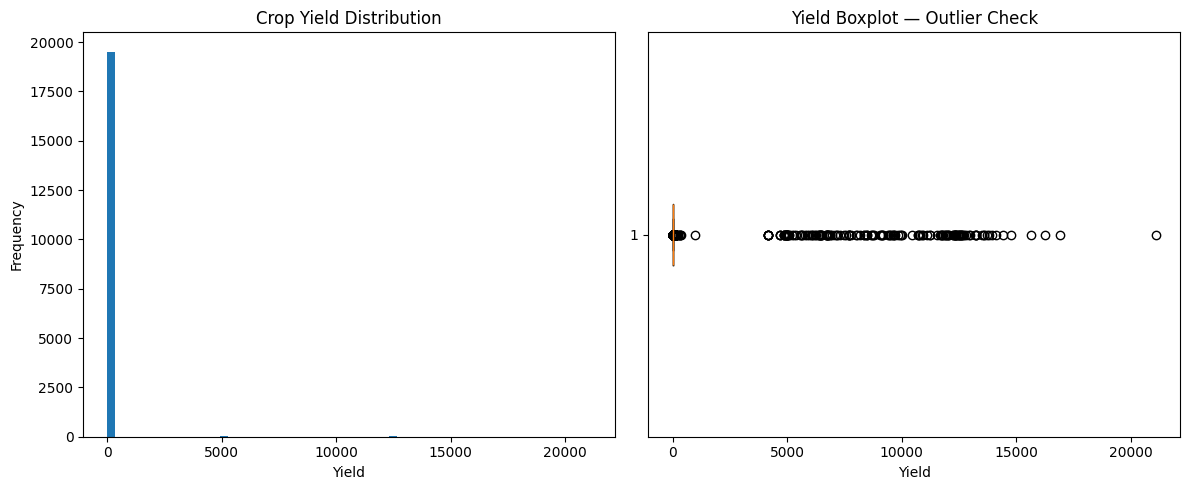

In [4]:
fig, axes = plt.subplots(1,2,figsize=(12,5))
axes[0].hist(df_no_target_na["Yield"],bins=60)
axes[0].set_title("Crop Yield Distribution")
axes[0].set_xlabel("Yield")
axes[0].set_ylabel("Frequency")
axes[1].boxplot(df_no_target_na["Yield"].dropna(),vert=False)
axes[1].set_title("Yield Boxplot — Outlier Check")
axes[1].set_xlabel("Yield")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"02_yield_distribution_and_boxplot.png",dpi=160)
plt.show()

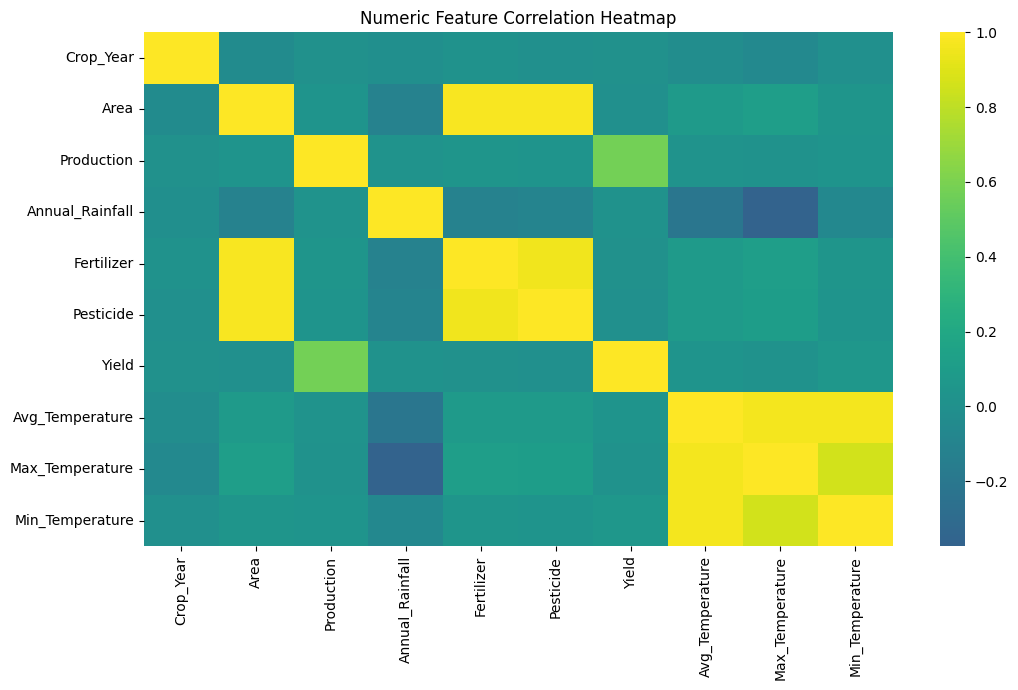

Top absolute correlations with Yield:


,abs_correlation
Production,0.570808
Min_Temperature,0.057605
Avg_Temperature,0.039344
Annual_Rainfall,0.020812
Max_Temperature,0.018738
Fertilizer,0.002859
Crop_Year,0.002532
Area,0.001857
Pesticide,0.001781


In [5]:
plt.figure(figsize=(11,7))
corr=df_no_target_na[numeric].corr(numeric_only=True)
sns.heatmap(corr,cmap="viridis",center=0)
plt.title("Numeric Feature Correlation Heatmap")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"04_correlation_heatmap.png",dpi=160); plt.show()
print("Top absolute correlations with Yield:")
display(corr["Yield"].drop("Yield").abs().sort_values(ascending=False).to_frame("abs_correlation"))

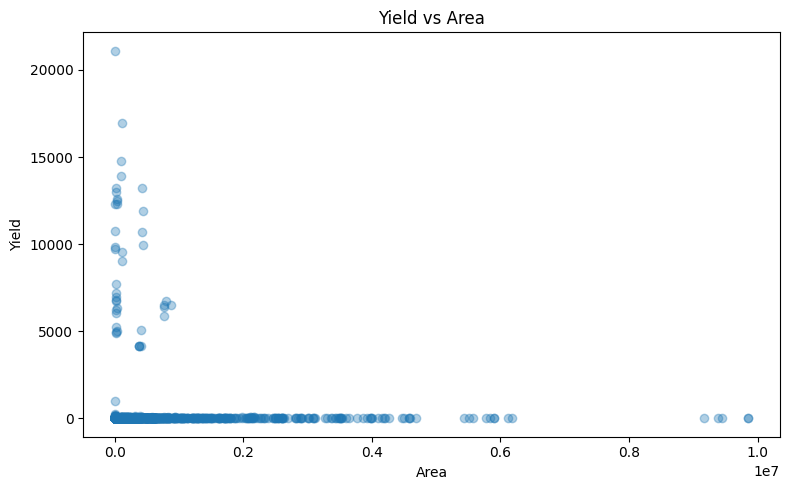

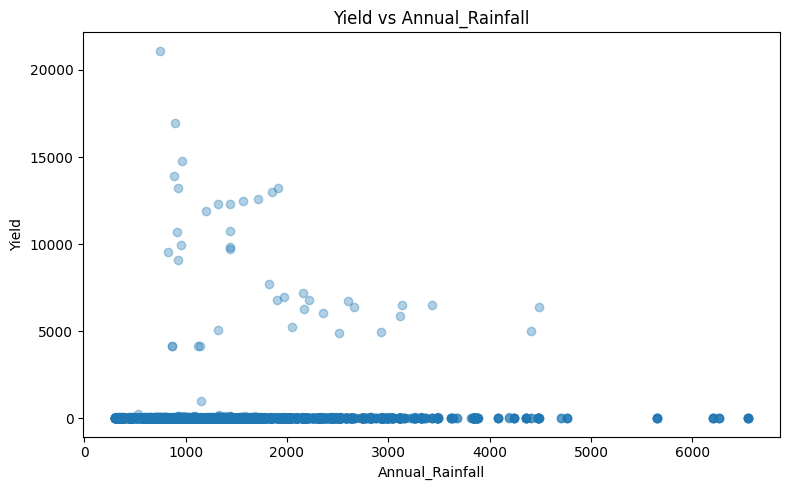

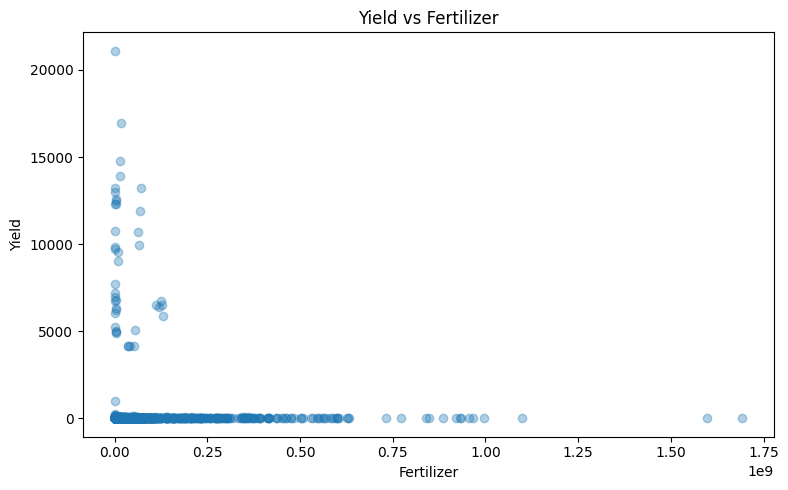

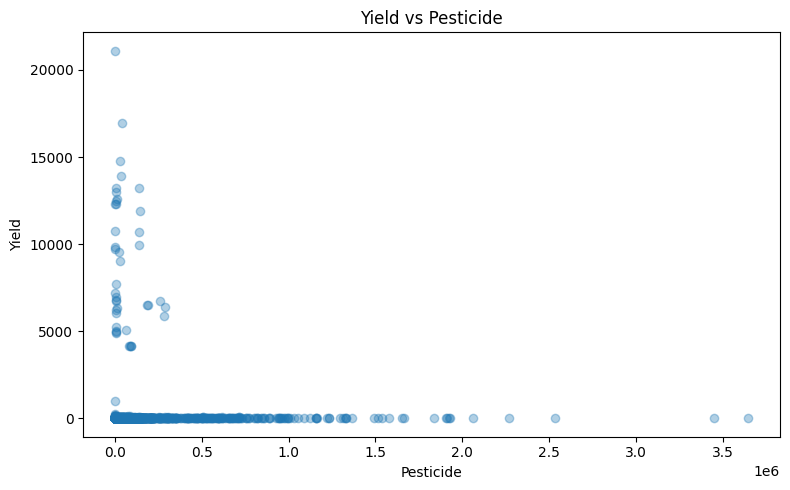

In [6]:
for col in ["Area","Annual_Rainfall","Fertilizer","Pesticide"]:
    sample=df_no_target_na.sample(min(5000,len(df_no_target_na)),random_state=42)
    plt.figure(figsize=(8,5))
    plt.scatter(sample[col],sample["Yield"],alpha=.35)
    plt.xlabel(col); plt.ylabel("Yield"); plt.title(f"Yield vs {col}")
    plt.tight_layout(); plt.savefig(OUTPUT_DIR/f"eda_yield_vs_{col}.png",dpi=160); plt.show()

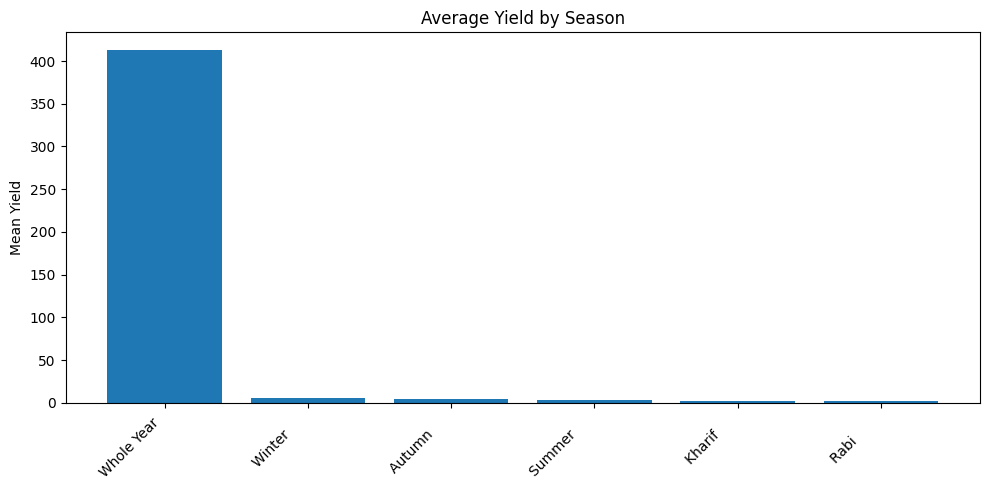

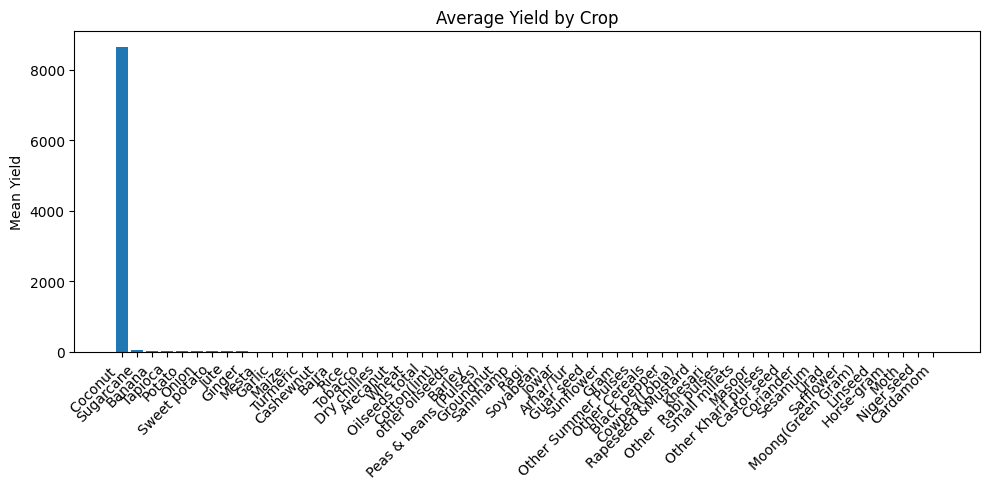

In [7]:
for col in ["Season","Crop"]:
    grouped=df_no_target_na.groupby(col)["Yield"].mean().sort_values(ascending=False)
    plt.figure(figsize=(10,5))
    plt.bar(grouped.index.astype(str),grouped.values)
    plt.xticks(rotation=45,ha="right"); plt.ylabel("Mean Yield"); plt.title(f"Average Yield by {col}")
    plt.tight_layout(); plt.savefig(OUTPUT_DIR/f"eda_average_yield_by_{col}.png",dpi=160); plt.show()

## EDA interpretation

The target is strongly right-skewed with extreme observations. Therefore, **MAE, RMSE and R² are all reported** rather than relying on one metric. Outliers are not blindly deleted because unusually high agricultural yields can be genuine observations. The modelling pipeline instead keeps the original target and uses robust evaluation metrics.